# NuCLS — EDA reproducible y control del piloto
Andrés Duarte Chaves · Entregable 1

Este notebook ejecuta análisis sobre las evidencias auditadas. No entrena redes: incorpora las quince corridas recibidas y verificadas del piloto. Las 17.999 observaciones son recortes de tres clases, no el dataset NuCLS completo.

In [1]:
from pathlib import Path
import json, sys, importlib.metadata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd().parent if Path.cwd().name == 'book' else Path.cwd()
assert (ROOT/'evidencias').exists()
versions = {p: importlib.metadata.version(p) for p in ['numpy','pandas','matplotlib','scikit-learn']}
print('Python:', sys.version.split()[0]); print(versions)
s = pd.read_csv(ROOT/'evidencias/seleccion_clases.csv')
q = pd.read_csv(ROOT/'evidencias/calidad_por_imagen.csv')
assert len(q)==1182 and q.paciente.nunique()==79
assert s.incluidas.sum()==17999
display(s)

Python: 3.12.14
{'numpy': '2.3.5', 'pandas': '2.2.3', 'matplotlib': '3.10.8', 'scikit-learn': '1.8.0'}


,particion,clase,origen,incluidas,retencion,porcentaje
0,entrenamiento,tumor_nonMitotic,13826,7089,0.512730,49.133629
1,entrenamiento,lymphocyte,9036,4162,0.460602,28.846687
2,entrenamiento,nonTILnonMQ_stromal,6607,3177,0.480854,22.019684
3,validacion,tumor_nonMitotic,3485,1646,0.472310,46.093531
4,validacion,lymphocyte,2629,1196,0.454926,33.492019
5,validacion,nonTILnonMQ_stromal,1582,729,0.460809,20.414450


## Balance y retención
Se conserva el número de anotaciones de origen como denominador. Las tasas de selección difieren por clase: no asumir representatividad automática. Macro-F1 y resultados por clase son necesarios.

particion
entrenamiento    14428
validacion        3571
Name: incluidas, dtype: int64
entrenamiento razón mayoritaria/minoritaria: 2.231 entropía (bits): 1.502
validacion razón mayoritaria/minoritaria: 2.258 entropía (bits): 1.512


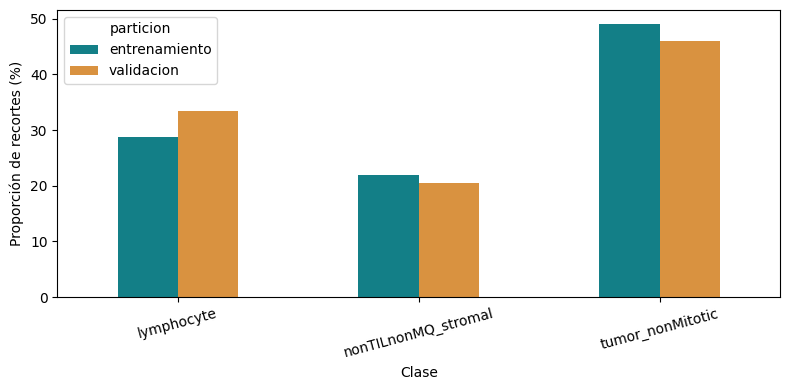

In [2]:
totales = s.groupby('particion').incluidas.sum()
print(totales)
for part, d in s.groupby('particion'):
    p=d.incluidas/d.incluidas.sum()
    print(part, 'razón mayoritaria/minoritaria:', round(d.incluidas.max()/d.incluidas.min(),3), 'entropía (bits):',round(float(-(p*np.log2(p)).sum()),3))
fig, ax=plt.subplots(figsize=(8,4))
s.pivot(index='clase',columns='particion',values='porcentaje').plot.bar(ax=ax,color=['#137f87','#d99240'])
ax.set_ylabel('Proporción de recortes (%)');ax.set_xlabel('Clase');plt.xticks(rotation=15);plt.tight_layout();plt.show()

## Calidad de campos
Los resúmenes corresponden a 1.182 campos de 79 pacientes. Cada campo tiene múltiples estructuras. Laplaciano, fondo y contraste son indicadores exploratorios y no criterios automáticos de exclusión.

,count,mean,std,min,5%,50%,95%,max
gris_media,1182.0,142.580565,25.135704,81.415197,103.308859,142.104353,185.162697,215.804190
gris_sd,1182.0,44.733025,9.315001,17.115270,31.898907,43.444166,62.071832,82.129751
saturacion_media,1182.0,0.333558,0.101825,0.078328,0.168296,0.330717,0.496520,0.592909
laplaciano_var_tejido,1182.0,117.895368,64.634006,10.652203,51.634726,107.824509,198.208322,662.038574
fondo_claro_235,1182.0,0.027534,0.047196,0.000000,0.000000,0.008627,0.119549,0.403425
entropia_gris,1182.0,7.333459,0.253810,5.732308,6.895610,7.352264,7.699318,7.881410


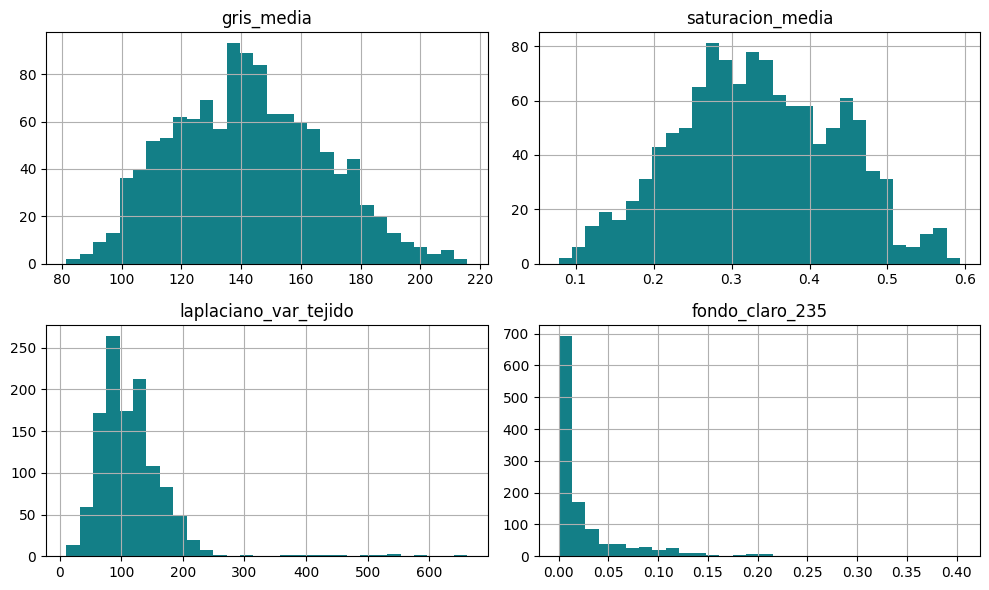

In [3]:
cols=['gris_media','gris_sd','saturacion_media','laplaciano_var_tejido','fondo_claro_235','entropia_gris']
display(q[cols].describe(percentiles=[.05,.5,.95]).T)
q[['gris_media','saturacion_media','laplaciano_var_tejido','fondo_claro_235']].hist(figsize=(10,6),bins=30,color='#137f87');plt.tight_layout();plt.show()

## Análisis multivariado por paciente
Medianas por paciente, log(1+x) del Laplaciano, centrado por mediana e IQR y covarianza robusta MCD. Percentil 95 empírico como regla de priorización exploratoria, no prueba de hipótesis. No se excluyen pacientes.

In [4]:
from sklearn.covariance import MinCovDet
p=q.groupby('paciente')[cols].median()
x=p.copy();x['laplaciano_var_tejido']=np.log1p(x['laplaciano_var_tejido'])
z=(x-x.median())/(x.quantile(.75)-x.quantile(.25))
assert np.isfinite(z.to_numpy()).all()
fit=MinCovDet(random_state=4101).fit(z)
p['distancia_robusta_cuadrada']=fit.mahalanobis(z)
cut=p.distancia_robusta_cuadrada.quantile(.95)
p['revision_prioritaria']=p.distancia_robusta_cuadrada>=cut
print('Umbral exploratorio:',round(cut,3),'Pacientes priorizados:',int(p.revision_prioritaria.sum()))
display(p.sort_values('distancia_robusta_cuadrada',ascending=False).head(8))

Umbral exploratorio: 571.393 Pacientes priorizados: 4


,gris_media,gris_sd,saturacion_media,laplaciano_var_tejido,fondo_claro_235,entropia_gris,distancia_robusta_cuadrada,revision_prioritaria
paciente,,,,,,,,
TCGA-E2-A158,171.582874,50.569681,0.247087,88.831233,0.142103,7.379393,1832.899056,True
TCGA-D8-A1JF,192.580969,39.740460,0.160135,128.871812,0.129501,7.125434,1375.204356,True
TCGA-D8-A1JL,184.690643,46.744740,0.161006,160.850962,0.105310,7.308998,808.566679,True
TCGA-D8-A13Z,174.278152,51.970326,0.207426,129.593453,0.095981,7.504947,689.500565,True
TCGA-D8-A1JG,186.864364,38.623603,0.186624,175.371506,0.090576,7.071130,558.269474,False
TCGA-E2-A1AZ,173.825614,45.616884,0.227434,180.336514,0.085033,7.393206,517.238550,False
TCGA-AO-A0J4,177.393708,40.168353,0.127723,30.724706,0.073514,7.288054,517.144893,False
TCGA-D8-A143,160.247883,59.366491,0.236257,98.390799,0.079477,7.614483,465.693865,False


## Auditoría de partición y duplicados exactos
Se leen los registros de preparación del piloto. Los hashes exactos no descartan similitud visual. Prueba y reserva no se utilizan aquí.

In [5]:
import zipfile
audit=json.loads((ROOT/'evidencias/CONTROL_PILOTO_QC_20261105_225210_resumen.json').read_text())
print('Pacientes por partición:',audit['pacientes_incluidos'])
print('Grupos duplicados exactos:',audit['grupos_duplicados_exactos'])
print('Duplicados entre grupos:',audit['duplicados_entre_grupos'])
for note in audit['limitaciones']:print('-',note)

Pacientes por partición: {'entrenamiento': 79, 'validacion': 19}
Grupos duplicados exactos: 0
Duplicados entre grupos: 0
- La elegibilidad favorece núcleos interiores. No representa todos los núcleos.
- Sin detección de casi duplicados. Recortes vecinos pueden solaparse dentro de un paciente.
- Prueba y reserva no leídas. Sin ajuste de filtros ni normalización de tinción.
- Las clases proceden de las anotaciones publicadas; no validadas de nuevo.


## Resultados predictivos: incorporación controlada
El archivo de resumen debe provenir del entrenador original. Las métricas de validación seleccionan época y no sustituyen prueba independiente. Cinco semillas estiman variabilidad algorítmica, no equivalen a cinco pacientes independientes.

In [6]:
f=ROOT/'resultados/resumen_modelos.csv'
if f.exists():
    results=pd.read_csv(f)
    assert {'modelo','ejecuciones','macro_f1_media','macro_f1_sd'}.issubset(results.columns)
    display(results)
    print('Revisar corridas completas antes de inferencia; no declarar superioridad con promedios aislados.')
else:
    print('PENDIENTE: incorporar resultados_RESULTADOS.zip del entrenamiento. No hay métricas predictivas inventadas.')

Revisar corridas completas antes de inferencia; no declarar superioridad con promedios aislados.


,modelo,ejecuciones,macro_f1_media,macro_f1_sd,cv
0,cnn_local,5,0.720346,0.010594,0.014707
1,resnet18,5,0.819057,0.010582,0.012920
2,mobilenet_v2,5,0.823934,0.007804,0.009472


## Conclusiones del análisis disponible
El EDA confirma heterogeneidad de campos y retención diferencial por clase. El uso de recortes interiores reduce artefactos de relleno, pero restringe el alcance de generalización. El control de agrupación es esencial. Quedan pendientes revisión visual de casos priorizados, casi duplicados, etiquetas, desplazamiento y diseño confirmatorio. Se incorpora análisis exploratorio del piloto completo. La literatura debe cerrar la elección de los tres baselines antes de la evaluación definitiva.

## Auditoría y comparación exploratoria del piloto completo
Las métricas se recalculan desde las predicciones. Bootstrap pareado por paciente, condicionado a los modelos y cinco semillas entrenados. No corrige el optimismo por selección de época en validación.

In [7]:
import runpy
runpy.run_path(str(ROOT/'scripts/analizar_piloto.py'),run_name='__main__')
display(pd.read_csv(ROOT/'resultados_analizados/resumen_verificado.csv'))
display(pd.read_csv(ROOT/'resultados_analizados/diferencias_bootstrap_paciente.csv'))

              n  macro_f1_media  macro_f1_sd  accuracy  auc_macro  minutos_media  parametros
modelo                                                                                      
cnn_local     5        0.720346     0.010594  0.766172   0.892474      16.732704       93635
resnet18      5        0.819057     0.010582  0.841837   0.951633      33.913438    11178051
mobilenet_v2  5        0.823934     0.007804  0.850182   0.953052      44.371271     2227715
    modelo_A  modelo_B  diferencia  ic95_inferior  ic95_superior
    resnet18 cnn_local    0.098711       0.068184       0.142751
mobilenet_v2 cnn_local    0.103588       0.079238       0.142843
mobilenet_v2  resnet18    0.004877      -0.010805       0.020088


,modelo,n,macro_f1_media,macro_f1_sd,accuracy,auc_macro,minutos_media,parametros
0,cnn_local,5,0.720346,0.010594,0.766172,0.892474,16.732704,93635
1,resnet18,5,0.819057,0.010582,0.841837,0.951633,33.913438,11178051
2,mobilenet_v2,5,0.823934,0.007804,0.850182,0.953052,44.371271,2227715


,modelo_A,modelo_B,diferencia,ic95_inferior,ic95_superior,alcance
0,resnet18,cnn_local,0.098711,0.068184,0.142751,Exploratorio; validación usada para elegir épo...
1,mobilenet_v2,cnn_local,0.103588,0.079238,0.142843,Exploratorio; validación usada para elegir épo...
2,mobilenet_v2,resnet18,0.004877,-0.010805,0.020088,Exploratorio; validación usada para elegir épo...


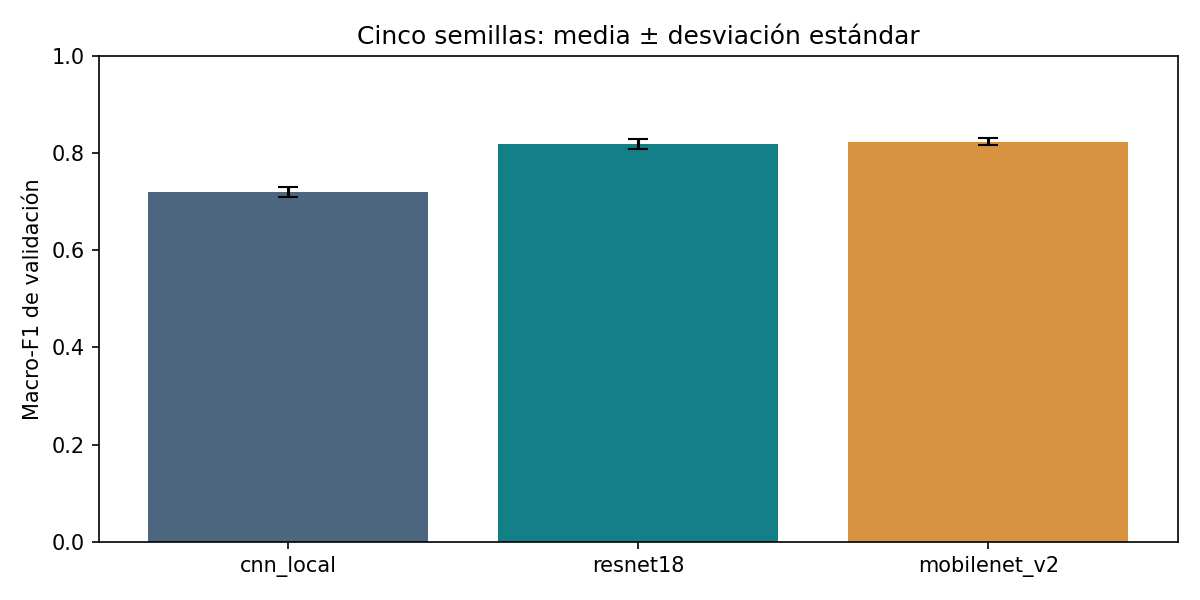

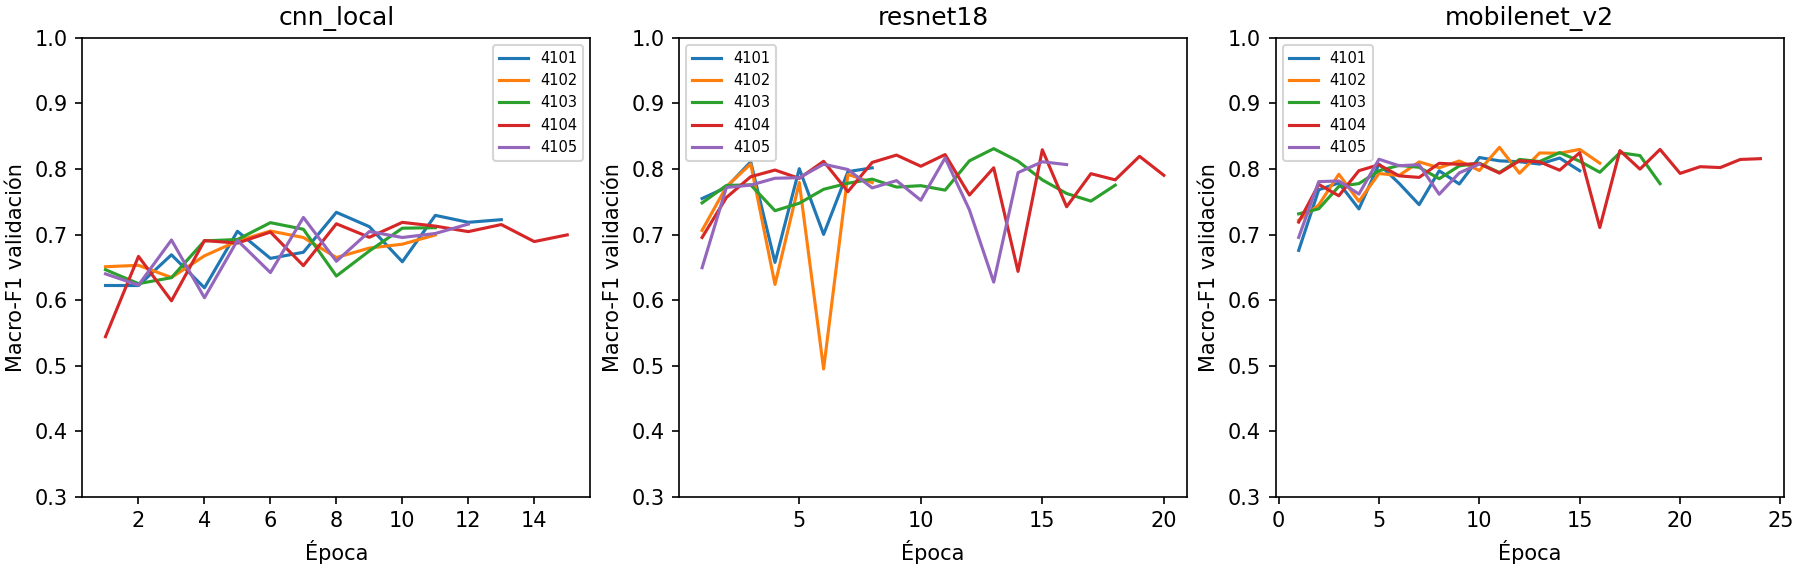

In [8]:
from IPython.display import Image, display
display(Image(filename=str(ROOT/'book/figuras/piloto_modelos.png')))
display(Image(filename=str(ROOT/'book/figuras/piloto_curvas.png')))

MobileNetV2 alcanza el promedio mayor, pero su diferencia de 0,00488 con ResNet18 es inferior al margen operativo de 0,02. La validación seleccionó época; estos resultados no confirman superioridad clínica ni desempeño externo. La clase estromal sigue siendo la más difícil por F1 promedio.

## Inspección visual y trazabilidad de ejemplos

Doce recortes de entrenamiento, cuatro por clase. Se conservan los ejemplos de la galería recibida; no es una nueva selección aleatoria ni una evaluación de predicciones. Los identificadores fueron contrastados con la partición del piloto. La siguiente celda verifica la integridad de los archivos incorporados.

Archivos verificados: 12
Clases: {'tumor_nonMitotic': 4, 'nonTILnonMQ_stromal': 4, 'lymphocyte': 4}


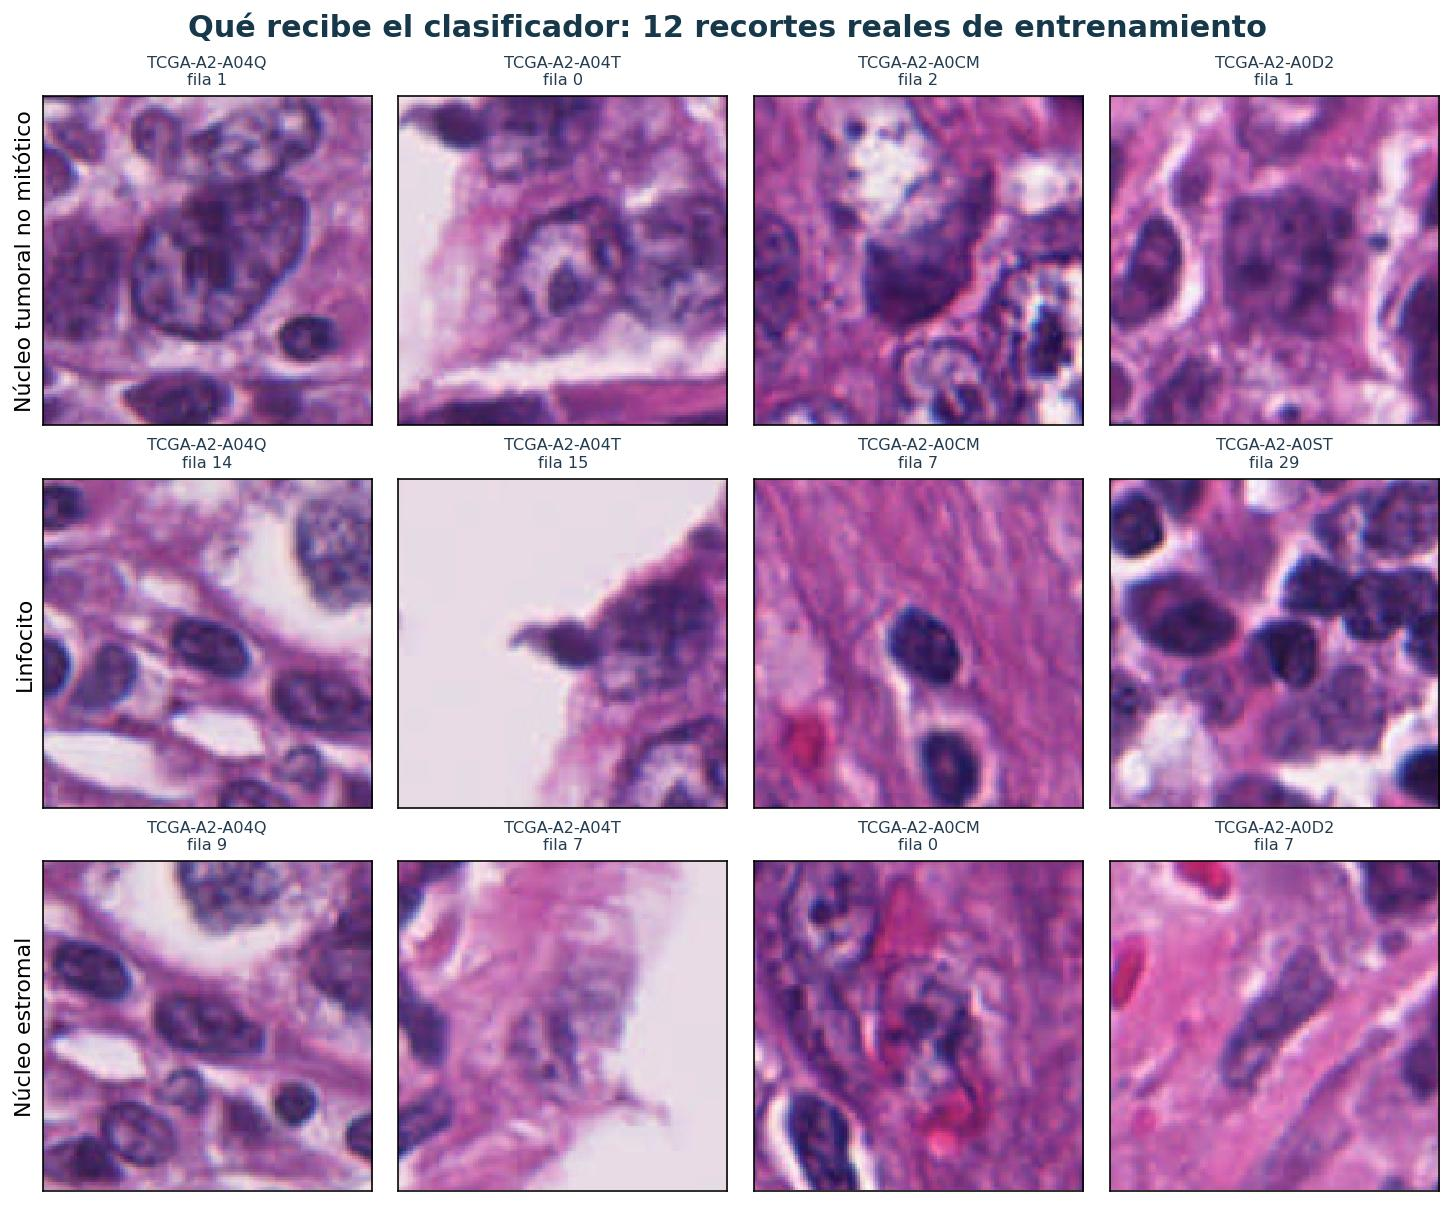

In [9]:
from pathlib import Path
import json, hashlib
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'evidencias/galeria_train.json').exists())
galeria = json.loads((root / 'evidencias/galeria_train.json').read_text())
from collections import Counter
for fila in galeria['registros']:
    contenido = (root / 'book/figuras/galeria' / fila['archivo']).read_bytes()
    assert hashlib.sha256(contenido).hexdigest() == fila['sha256']
    assert fila['particion'] == 'entrenamiento'
print('Archivos verificados:', len(galeria['registros']))
print('Clases:', dict(Counter(x['clase'] for x in galeria['registros'])))
from IPython.display import Image, display
display(Image(filename=str(root / 'book/figuras/galeria_train.jpg')))
